# Spam dataset with ensemble methods

### Importing packages

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
import xgboost
from xgboost import XGBClassifier

np.random.seed(0)

### Plotting functions

In [2]:
# Some functions to plot our points and draw the boundaries
def plot_points(features, labels, fix_margins=True):
    X = np.array(features)
    y = np.array(labels)
    spam = X[np.argwhere(y==1)]
    ham = X[np.argwhere(y==0)]
    if fix_margins:
        plt.xlim(0, 11)
        plt.ylim(0, 11)
    plt.scatter([s[0][0] for s in spam],
                [s[0][1] for s in spam],
                s = 100,
                color = 'cyan',
                edgecolor = 'k',
                marker = '^')
    plt.scatter([s[0][0] for s in ham],
                [s[0][1] for s in ham],
                s = 100,
                color = 'red',
                edgecolor = 'k',
                marker = 's')
    plt.xlabel('Lottery')
    plt.ylabel('Sale')
    plt.legend(['Spam','Ham'])

def plot_model(X, y, model, fix_margins=True):
    X = np.array(X)
    y = np.array(y)
    plot_points(X, y)
    plot_step = 0.01
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    if fix_margins:
        x_min=0
        y_min=0
        x_max=12
        y_max=12
    xx, yy = np.meshgrid(np.arange(x_min, x_max, plot_step),
                         np.arange(y_min, y_max, plot_step))
    grid = np.c_[xx.ravel(), yy.ravel()]
    if hasattr(model, 'feature_names_in_'):  # models trained on a DataFrame expect column names
        grid = pd.DataFrame(grid, columns=model.feature_names_in_)
    Z = np.array(model.predict(grid)).reshape(xx.shape)
    plt.contourf(xx, yy, Z, colors=['red', 'blue'], alpha=0.2, levels=range(-1,2))
    if Z.min() != Z.max():  # draw the boundary only if the model predicts both classes
        plt.contour(xx, yy, Z, colors='k', linewidths=3)
    plt.show()

def plot_decision_tree(dt):
    plt.figure(figsize=(12, 6))
    tree.plot_tree(dt, feature_names=['Lottery', 'Sale'], filled=True, rounded=True, precision=3)
    plt.show()

# The spam email dataset

In [3]:
emails = np.array([
    [7,8,1],
    [3,2,0],
    [8,4,1],
    [2,6,0],
    [6,5,1],
    [9,6,1],
    [8,5,0],
    [7,1,0],
    [1,9,1],
    [4,7,0],
    [1,3,0],
    [3,10,1],
    [2,2,1],
    [9,3,0],
    [5,3,0],
    [10,1,0],
    [5,9,1],
    [10,8,1],
])
spam_dataset = pd.DataFrame(data=emails, columns=["Lottery", "Sale", "Spam"])
spam_dataset

,Lottery,Sale,Spam
0,7,8,1
1,3,2,0
2,8,4,1
3,2,6,0
4,6,5,1
5,9,6,1
6,8,5,0
7,7,1,0
8,1,9,1
9,4,7,0


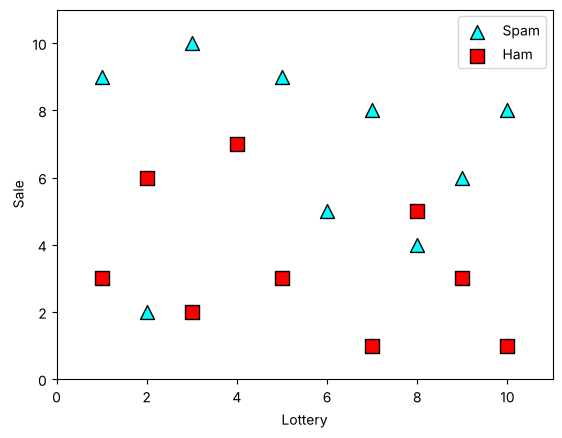

In [4]:
features = spam_dataset[['Lottery', 'Sale']]
labels = spam_dataset['Spam']
plot_points(features, labels)

In [5]:
decision_tree_classifier = DecisionTreeClassifier(random_state=0)
decision_tree_classifier.fit(features, labels)
decision_tree_classifier.score(features, labels)

1.0

# Training a decision tree

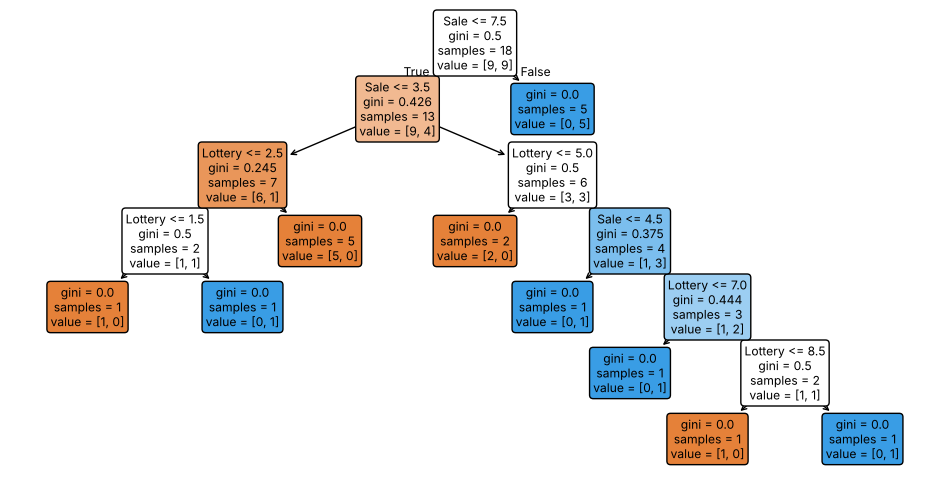

In [6]:
plot_decision_tree(decision_tree_classifier)

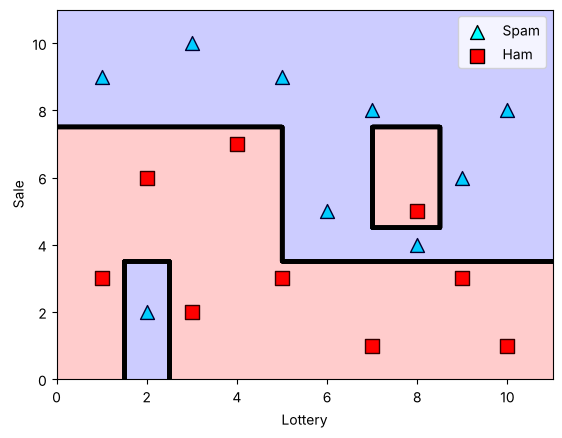

In [7]:
plot_model(features, labels, decision_tree_classifier)

# Training a random forest by hand

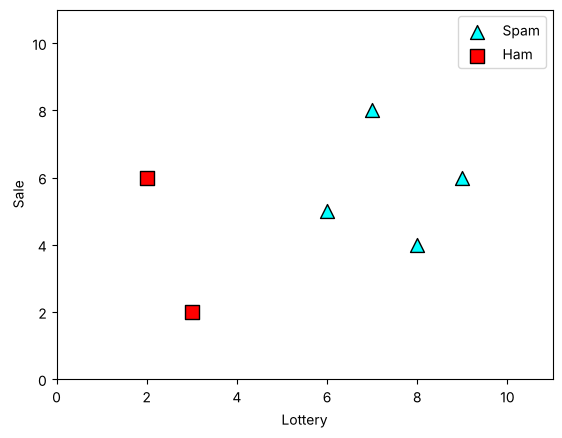

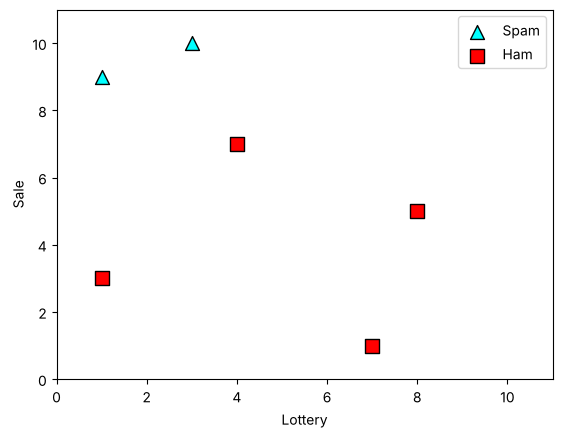

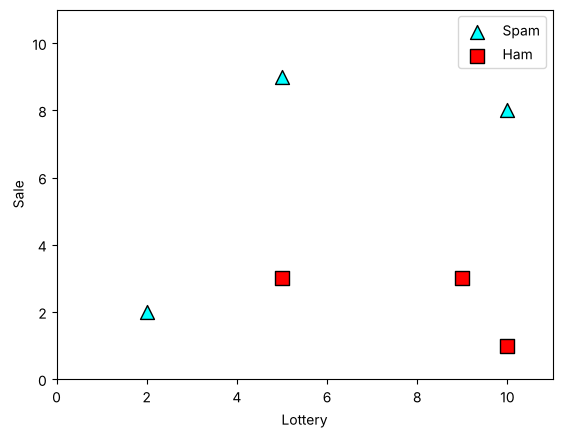

In [8]:
first_batch = spam_dataset.loc[[0,1,2,3,4,5]]
features1 = first_batch[['Lottery', 'Sale']]
labels1 = first_batch['Spam']
plot_points(features1, labels1)
plt.show()

second_batch = spam_dataset.loc[[6,7,8,9,10,11]]
features2 = second_batch[['Lottery', 'Sale']]
labels2 = second_batch['Spam']
plot_points(features2, labels2)
plt.show()

third_batch = spam_dataset.loc[[12,13,14,15,16,17]]
features3 = third_batch[['Lottery', 'Sale']]
labels3 = third_batch['Spam']
plot_points(features3, labels3)

Weak learner 1 training accuracy: 1.0


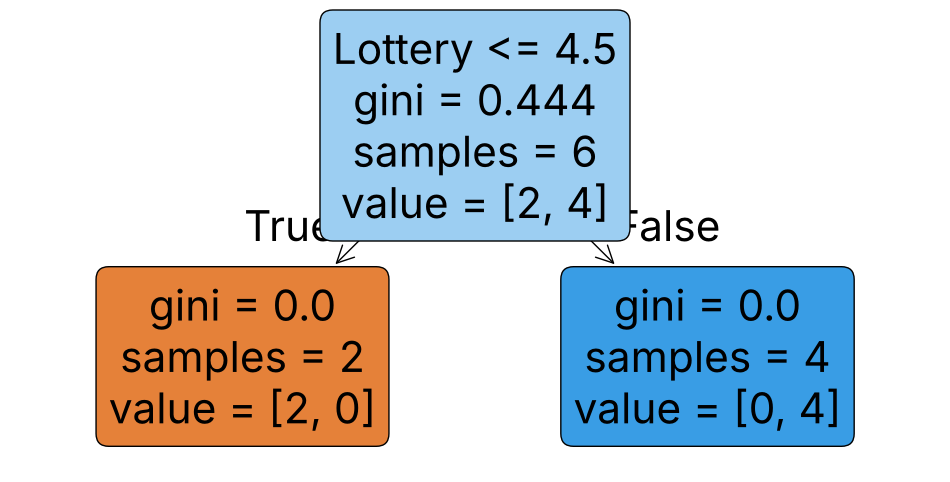

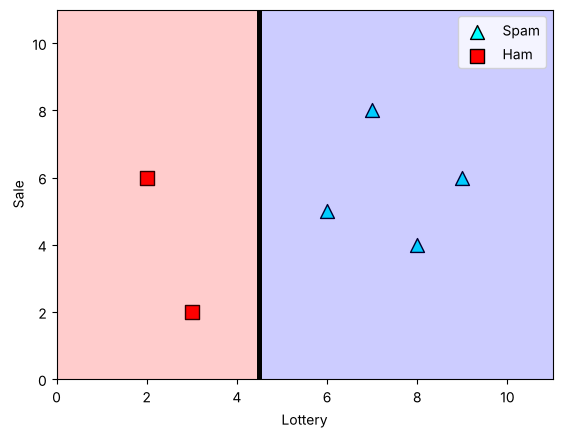

Weak learner 2 training accuracy: 1.0


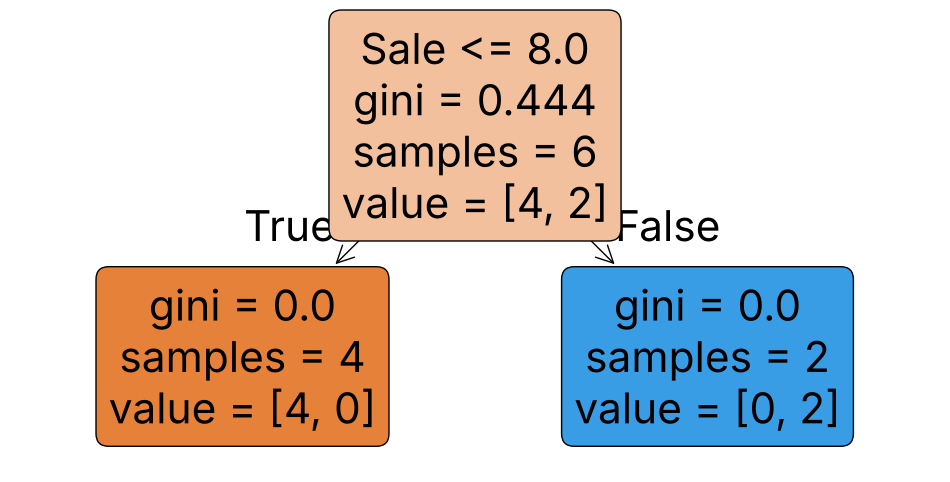

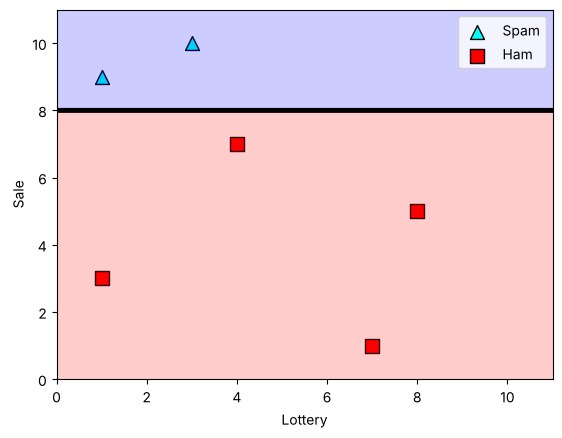

Weak learner 3 training accuracy: 0.8333333333333334


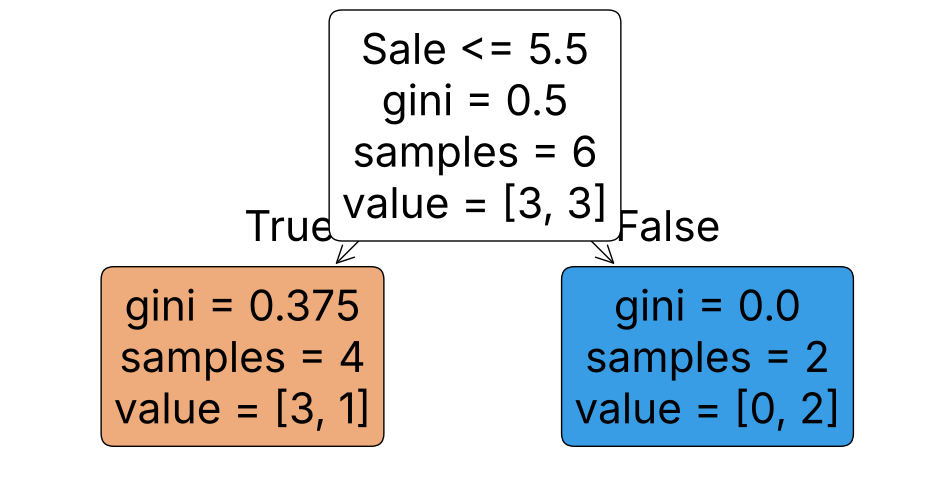

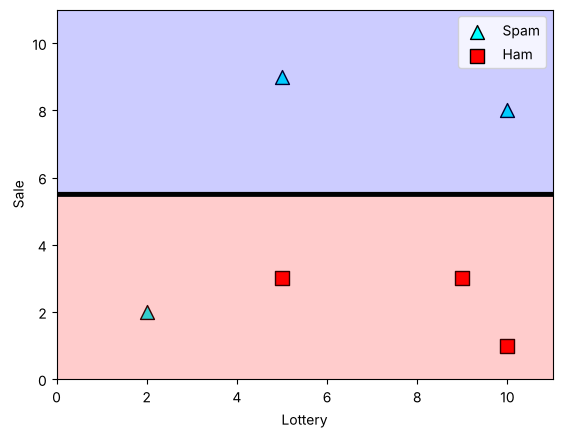

In [9]:
dt1 = DecisionTreeClassifier(random_state=0, max_depth=1)
dt1.fit(features1, labels1)
print("Weak learner 1 training accuracy:", dt1.score(features1, labels1))
plot_decision_tree(dt1)
plot_model(features1, labels1, dt1)

dt2 = DecisionTreeClassifier(random_state=0, max_depth=1)
dt2.fit(features2, labels2)
print("Weak learner 2 training accuracy:", dt2.score(features2, labels2))
plot_decision_tree(dt2)
plot_model(features2, labels2, dt2)

dt3 = DecisionTreeClassifier(random_state=0, max_depth=1)
dt3.fit(features3, labels3)
print("Weak learner 3 training accuracy:", dt3.score(features3, labels3))
plot_decision_tree(dt3)
plot_model(features3, labels3, dt3)

# Training a random forest using sklearn

In [10]:
random_forest_classifier = RandomForestClassifier(random_state=0, n_estimators=5, max_depth=1)
random_forest_classifier.fit(features, labels)
random_forest_classifier.score(features, labels)
# Expected output: 0.8333333333333334

0.8333333333333334

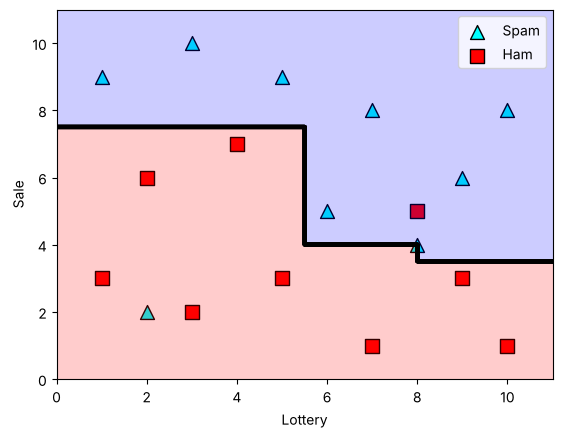

In [11]:
plot_model(features, labels, random_forest_classifier)

****************************** Weak learner 1 ******************************


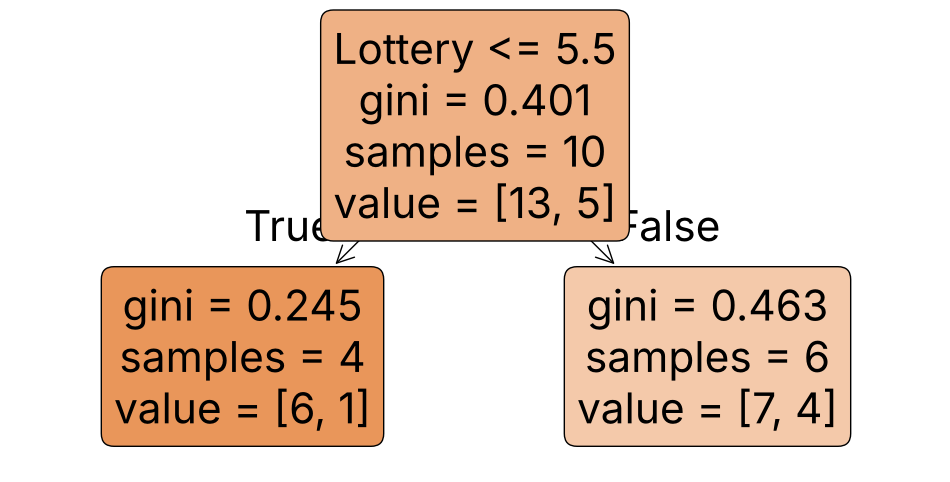

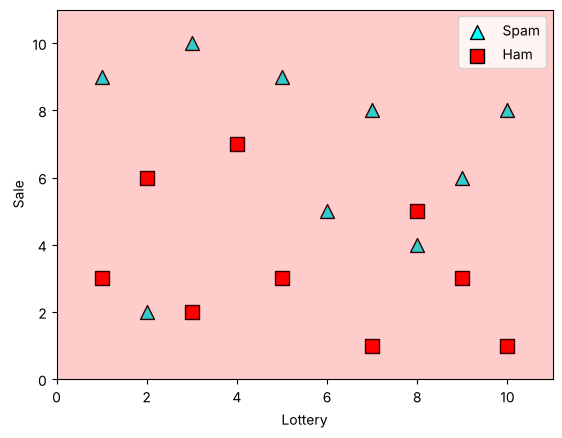

****************************** Weak learner 2 ******************************


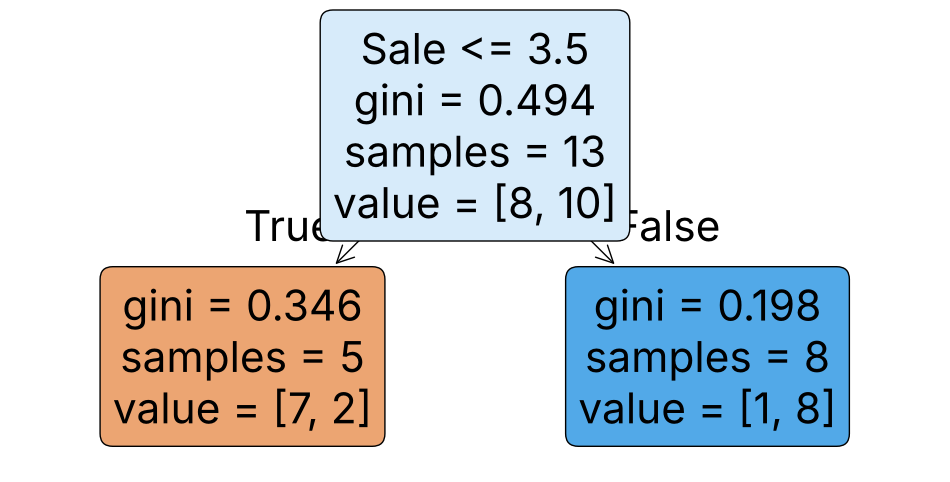

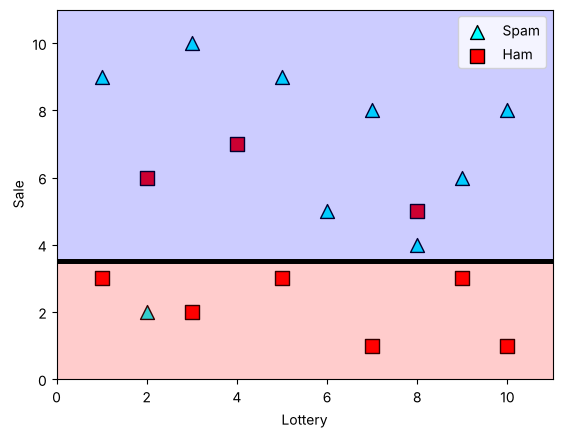

****************************** Weak learner 3 ******************************


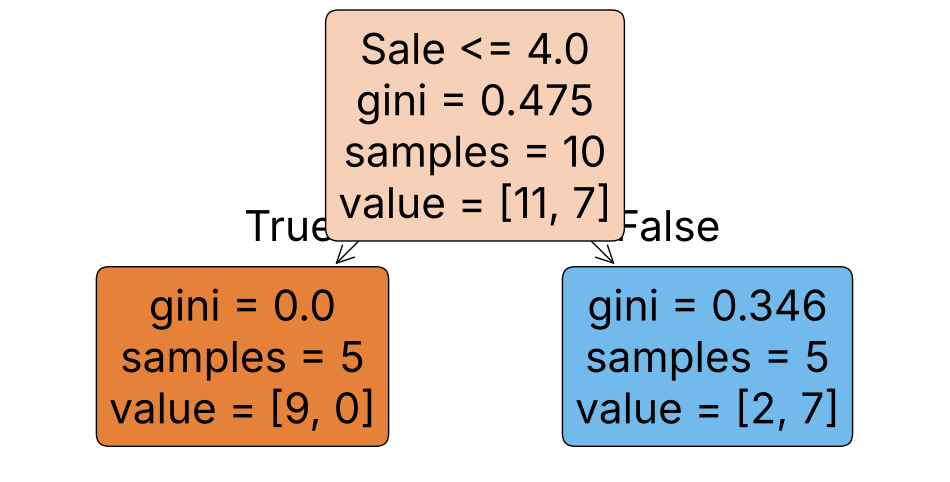

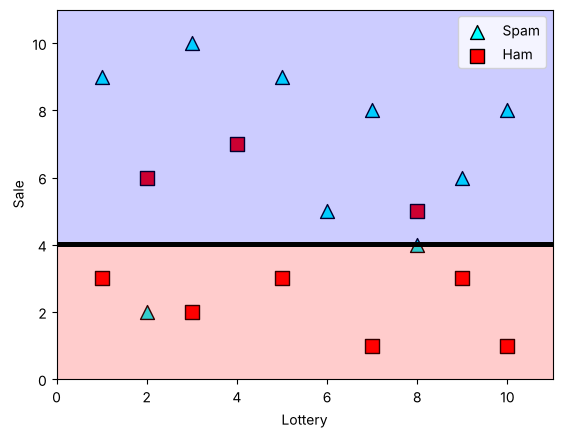

****************************** Weak learner 4 ******************************


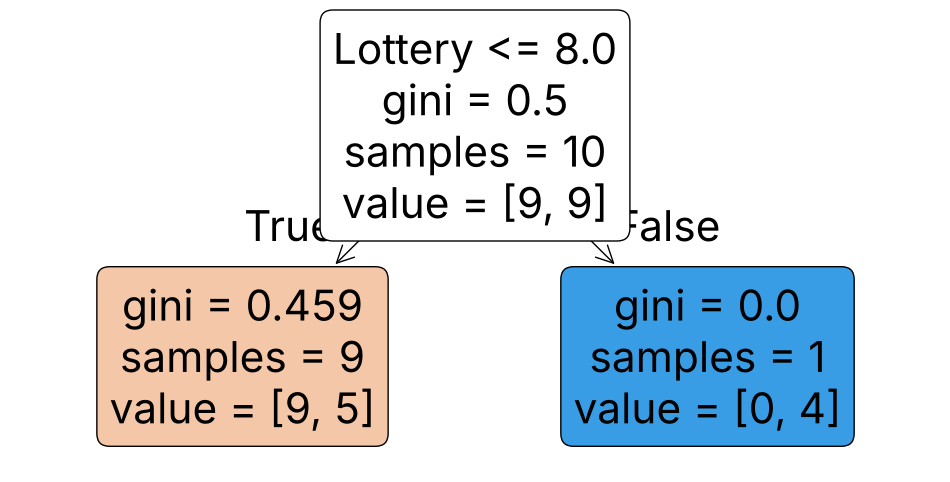

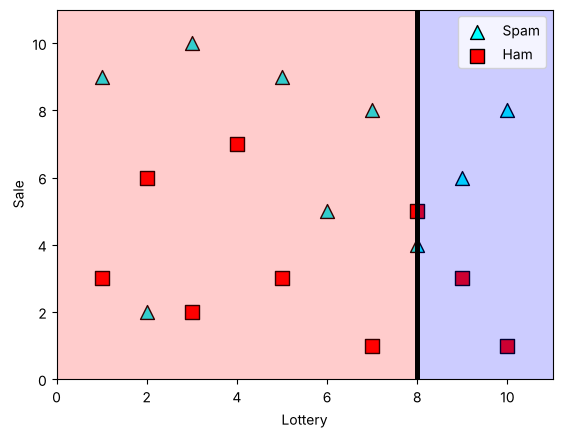

****************************** Weak learner 5 ******************************


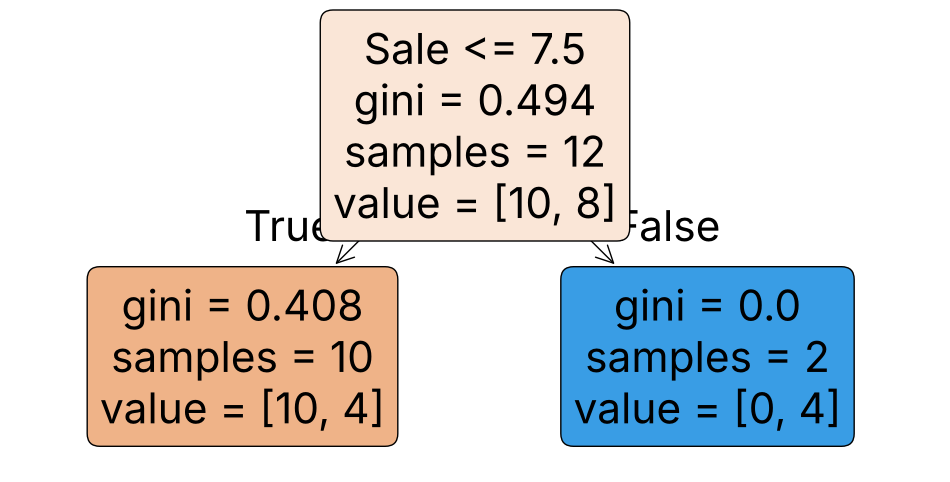

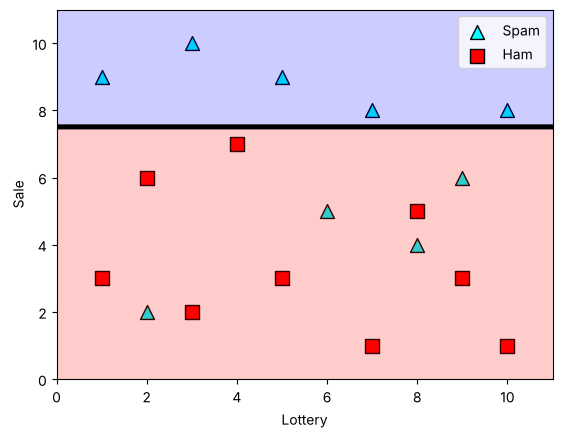

In [12]:
for i, dt in enumerate(random_forest_classifier.estimators_):
    print("*"*30, "Weak learner", i+1, "*"*30)
    plot_decision_tree(dt)
    plot_model(features, labels, dt)

# AdaBoost

In [13]:
# Set the random_state so that we always get the same results
adaboost_classifier = AdaBoostClassifier(random_state=0, n_estimators=6)
adaboost_classifier.fit(features, labels)
adaboost_classifier.score(features, labels)
# Expected output: 0.7777777777777778

0.7777777777777778

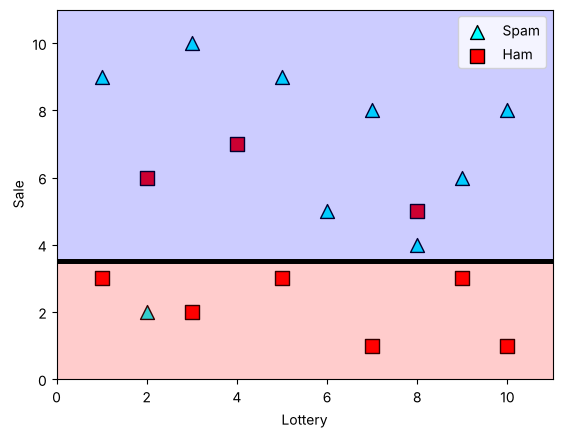

In [14]:
plot_model(features, labels, adaboost_classifier)

Weak learner 1 score: 1.253


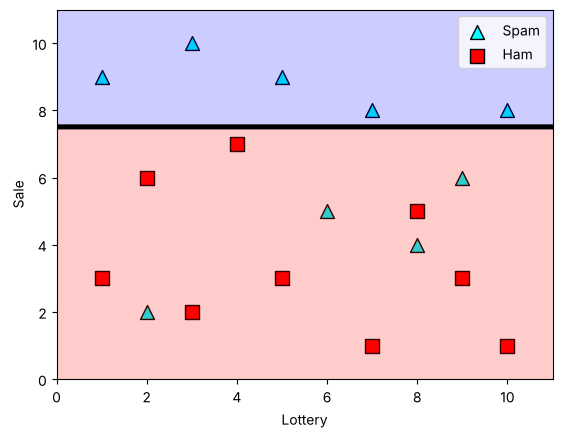

Weak learner 2 score: 1.196


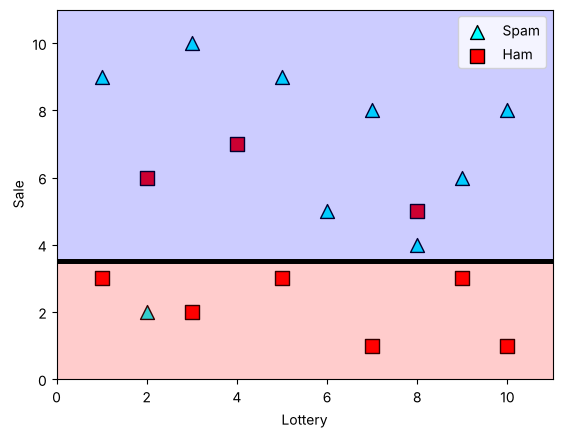

Weak learner 3 score: 0.736


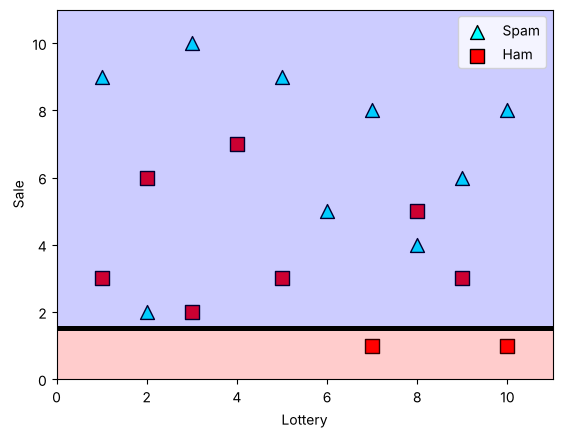

Weak learner 4 score: 0.677


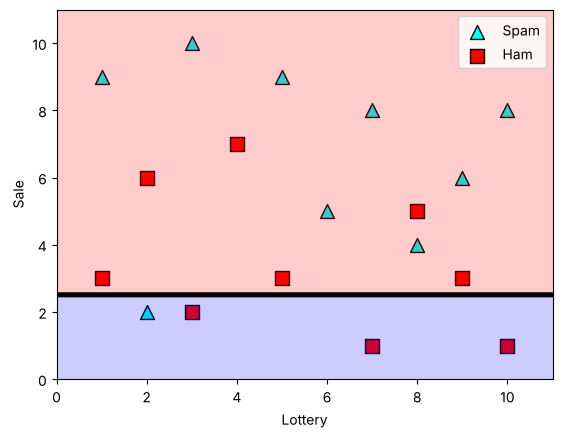

Weak learner 5 score: 0.331


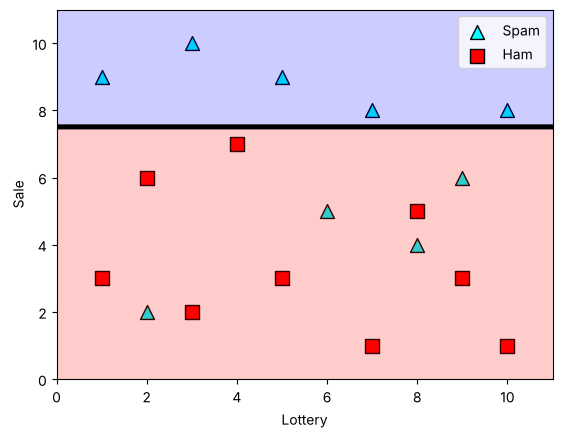

Weak learner 6 score: 0.446


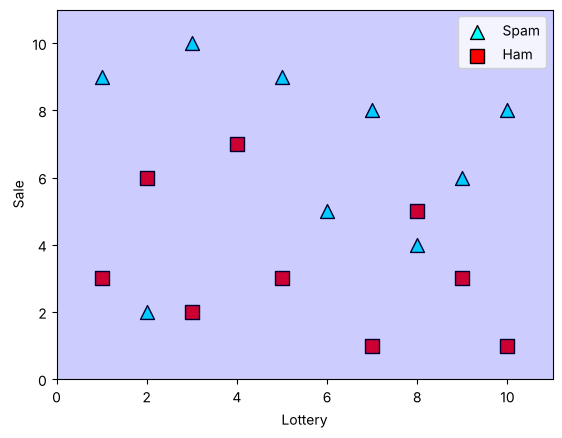

In [15]:
# The six weak learners and their scores (the log-odds of their weighted accuracy)
for i, (estimator, score) in enumerate(zip(adaboost_classifier.estimators_, adaboost_classifier.estimator_weights_)):
    print("Weak learner", i+1, "score:", round(float(score), 3))
    plot_model(features, labels, estimator)

# Bonus: applying gradient boosting and XGBoost to the spam dataset

Note: the chapter covers these algorithms in regression mode on a different dataset, but here are the results of applying gradient boosting and XGBoost to this spam dataset. Notice that both models give predictions that are accurate, yet far from overfitting, which is a characteristic of boosting models.

# Gradient boosting

In [16]:
gradient_boosting_classifier = GradientBoostingClassifier(random_state=0, n_estimators=5)
gradient_boosting_classifier.fit(features, labels)
gradient_boosting_classifier.score(features, labels)

0.8888888888888888

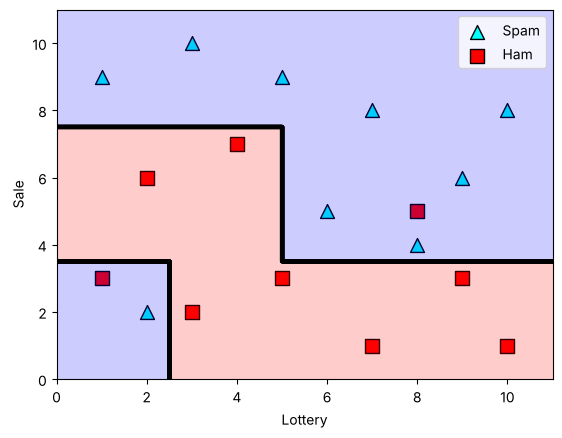

In [17]:
plot_model(features, labels, gradient_boosting_classifier)

In [18]:
estimators = gradient_boosting_classifier.estimators_

As an example, let us plot the first of the estimators.

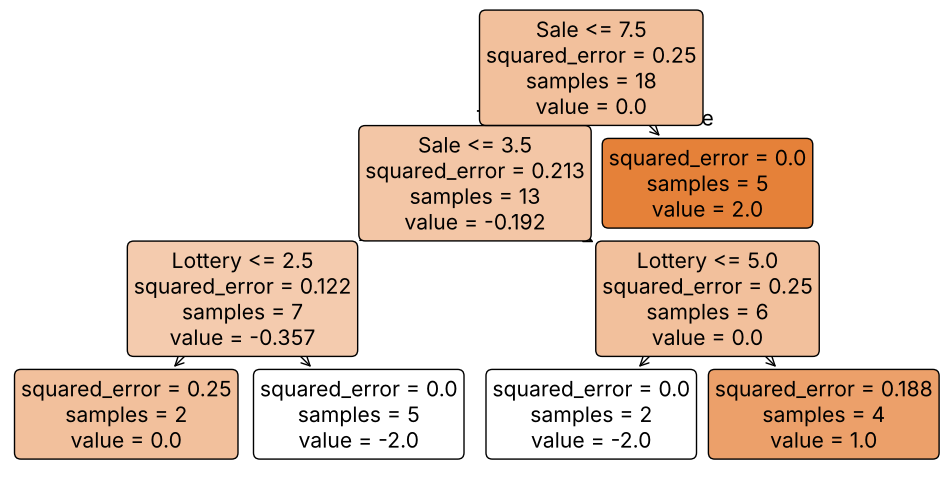

In [19]:
plt.figure(figsize=(12, 6))
tree.plot_tree(estimators[0][0], feature_names=['Lottery', 'Sale'], filled=True, rounded=True, precision=3)
plt.show()

# XGBoost

In [20]:
xgboost_classifier = XGBClassifier(random_state=0, n_estimators=5)
xgboost_classifier.fit(features, labels)
xgboost_classifier.score(features, labels)

0.8888888888888888

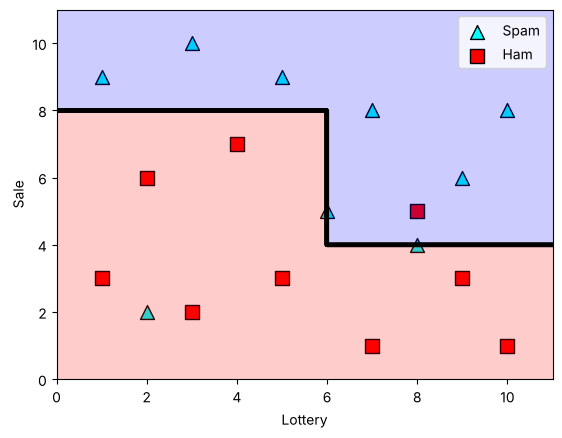

In [21]:
plot_model(features, labels, xgboost_classifier)

Here is the first of the estimators

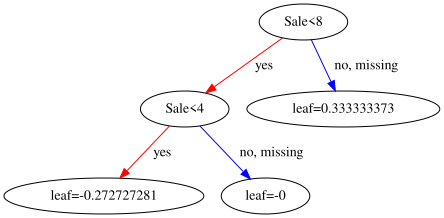

In [22]:
xgboost.to_graphviz(xgboost_classifier, tree_idx=0)